# 05 — Conectividade: efeito de sítio nas tarefas dentro de cada base

No notebook 04, TDAH × Controle dentro do ADHD-200 ficou **abaixo do acaso** (0,40–0,44) com validação por
instituição, sinal de efeito de sítio. Duas correções:

1. **Recuperar controles.** `harmonize()` manteve a cópia do ABIDE dos controles do NYU e do KKI que estão nas duas
   bases. Para a tarefa dentro do ADHD-200, usamos a cópia do Athena desses controles.
2. **Padronizar cada feature dentro da instituição** (`standardize_by_group` em `src/connectivity.py`), sem usar
   rótulos. Cada instituição usa só os próprios dados, então não há vazamento entre treino e teste.

Também testamos o ADHD-200 só com as instituições que têm as duas classes (Pittsburgh e WashU quase não têm TDAH)
e aplicamos a padronização ao TEA × Controle do ABIDE I, para comparar com o notebook 04.

Mesma validação do notebook 04: `GroupKFold` por instituição, 5 dobras, 3 repetições.

In [1]:
import sys
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from connectivity import standardize_by_group
from evaluation import make_models_conn, metrics_binary, repeated_group_cv
from harmonize import INSTITUTION, load_adhd200

warnings.filterwarnings("ignore")
FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEEDS = range(3)

npz = np.load(ROOT / "data" / "processed" / "connectivity_aal.npz", allow_pickle=True)
FC = pd.DataFrame(npz["X"], index=npz["subject_id"])

# ADHD-200 sem a remoção de duplicados entre bases (recupera os controles que também estão no ABIDE)
adhd = load_adhd200()
adhd = adhd[adhd.diagnosis.notna() & adhd.age.between(7, 21) & adhd.subject_id.isin(FC.index)].copy()
adhd["institution"] = adhd.site.replace(INSTITUTION)
adhd = adhd.set_index("subject_id")

# ABIDE I: mesma coorte do notebook 04
coorte = pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv").set_index("subject_id")
abide = coorte[(coorte.release == "ABIDE_I") & coorte.index.isin(FC.index)]

print("ADHD-200 (com controles recuperados):")
print(pd.crosstab(adhd.institution, adhd.diagnosis, margins=True))

ADHD-200 (com controles recuperados):
diagnosis    Controle  TDAH  All
institution                     
KKI                58    22   80
NYU                97   128  225
NeuroIMAGE         30    30   60
OHSU               64    40  104
Peking            141    99  240
Pittsburgh         92     4   96
WashU              48     0   48
All               530   323  853


## 1. Cenários

In [2]:
def cenario(d, positivo, padronizar, excluir=()):
    d = d[~d.institution.isin(excluir)]
    X = FC.loc[d.index].to_numpy()
    if padronizar:
        X = standardize_by_group(X, d.institution.to_numpy())
    y = (d.diagnosis == positivo).astype(int).to_numpy()
    return X, y, d.institution.to_numpy()

so_uma_classe = ["Pittsburgh", "WashU"]
CENARIOS = {
    "TDAH × Controle | bruto": (adhd, "TDAH", False, ()),
    "TDAH × Controle | padronizado por instituição": (adhd, "TDAH", True, ()),
    "TDAH × Controle | padronizado, sem Pittsburgh/WashU": (adhd, "TDAH", True, so_uma_classe),
    "TEA × Controle | bruto": (abide, "TEA", False, ()),
    "TEA × Controle | padronizado por instituição": (abide, "TEA", True, ()),
}

res = {}
for nome, (d, pos, padr, exc) in CENARIOS.items():
    X, y, g = cenario(d, pos, padr, exc)
    print(f"{nome}: {len(y)} sujeitos ({y.sum()} {pos}), {len(set(g))} instituições")
    for m_nome, m in make_models_conn().items():
        r, _ = repeated_group_cv(m, X, y, g, seeds=SEEDS, metric_fn=partial(metrics_binary, nomes=("Controle", "caso")))
        res[(nome, m_nome)] = r

TDAH × Controle | bruto: 853 sujeitos (323 TDAH), 7 instituições


TDAH × Controle | padronizado por instituição: 853 sujeitos (323 TDAH), 7 instituições


TDAH × Controle | padronizado, sem Pittsburgh/WashU: 709 sujeitos (319 TDAH), 5 instituições


TEA × Controle | bruto: 732 sujeitos (345 TEA), 17 instituições


TEA × Controle | padronizado por instituição: 732 sujeitos (345 TEA), 17 instituições


## 2. Resultados

In [3]:
tab = pd.DataFrame({k: r.drop(columns="semente").mean() for k, r in res.items()}).T
tab.index.names = ["cenário", "modelo"]
tab["acc_bal_dp"] = [r.acc_balanceada.std() for r in res.values()]
tab = tab[["acc_balanceada", "acc_bal_dp", "sens_caso", "espec_Controle", "auc"]]
tab.round(3)

acc_balanceada  \
cenário                                            modelo                                
TDAH × Controle | bruto                            Regressão logística           0.453   
                                                   Árvore de decisão             0.446   
                                                   Random Forest                 0.454   
                                                   XGBoost                       0.448   
TDAH × Controle | padronizado por instituição      Regressão logística           0.502   
                                                   Árvore de decisão             0.499   
                                                   Random Forest                 0.493   
                                                   XGBoost                       0.475   
TDAH × Controle | padronizado, sem Pittsburgh/W... Regressão logística           0.534   
                                                   Árvore de decisão             0.503   
                                                   Random Forest                 0.524   
                                                   XGBoost                       0.507   
TEA × Controle | bruto                             Regressão logística           0.641   
                                                   Árvore de decisão             0.527   
                                                   Random Forest                 0.610   
                                                   XGBoost                       0.627   
TEA × Controle | padronizado por instituição       Regressão logística           0.645   
                                                   Árvore de decisão             0.552   
                                                   Random Forest                 0.610   
                                                   XGBoost                       0.639   

                                                                        acc_bal_dp  \
cenário                                            modelo                            
TDAH × Controle | bruto                            Regressão logística       0.010   
                                                   Árvore de decisão         0.030   
                                                   Random Forest             0.006   
                                                   XGBoost                   0.007   
TDAH × Controle | padronizado por instituição      Regressão logística       0.013   
                                                   Árvore de decisão         0.013   
                                                   Random Forest             0.020   
                                                   XGBoost                   0.018   
TDAH × Controle | padronizado, sem Pittsburgh/W... Regressão logística       0.000   
                                                   Árvore de decisão         0.000   
                                                   Random Forest             0.000   
                                                   XGBoost                   0.000   
TEA × Controle | bruto                             Regressão logística       0.018   
                                                   Árvore de decisão         0.006   
                                                   Random Forest             0.010   
                                                   XGBoost                   0.011   
TEA × Controle | padronizado por instituição       Regressão logística       0.014   
                                                   Árvore de decisão         0.019   
                                                   Random Forest             0.015   
                                                   XGBoost                   0.013   

                                                                        sens_caso  \
cenário                                            modelo                           
TDAH × Controle | bruto     

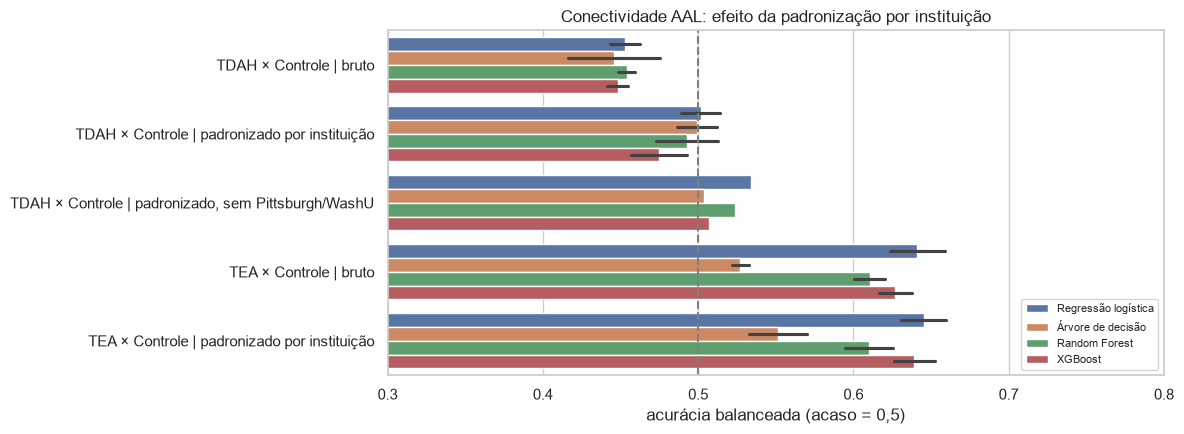

In [4]:
longo = pd.concat([r.assign(cenario=k[0], modelo=k[1]) for k, r in res.items()])
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=longo, y="cenario", x="acc_balanceada", hue="modelo", errorbar="sd", ax=ax, orient="h")
ax.axvline(0.5, ls="--", c="gray"); ax.set_xlim(0.3, 0.8); ax.set_ylabel(""); ax.set_xlabel("acurácia balanceada (acaso = 0,5)")
ax.set_title("Conectividade AAL: efeito da padronização por instituição"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "05_padronizacao_por_instituicao.png", dpi=150)

## 3. Leitura dos resultados (execução de 25/11/2026)

Acurácia balanceada (acaso = 0,50); entre parênteses, AUC.

| Cenário | Regressão logística | Árvore | Random Forest | XGBoost |
|---|---|---|---|---|
| TDAH × Controle, bruto (com controles recuperados) | 0,45 (0,42) | 0,45 (0,46) | 0,45 (0,40) | 0,45 (0,40) |
| TDAH × Controle, padronizado por instituição | 0,50 (0,49) | 0,50 (0,51) | 0,49 (0,49) | 0,48 (0,45) |
| TDAH × Controle, padronizado, sem Pittsburgh/WashU | **0,53** (0,54) | 0,50 (0,53) | 0,52 (0,53) | 0,51 (0,50) |
| TEA × Controle, bruto | 0,64 (0,69) | 0,53 (0,53) | 0,61 (0,66) | 0,63 (0,68) |
| TEA × Controle, padronizado por instituição | **0,65** (0,70) | 0,55 (0,57) | 0,61 (0,67) | 0,64 (0,69) |

- **Recuperar os controles não bastou** para o ADHD-200: continuou abaixo do acaso (0,45).
- **A padronização por instituição eliminou o "abaixo do acaso"** (0,48–0,50), confirmando que o problema era efeito
  de sítio, mas não revelou sinal de TDAH.
- **Só com instituições que têm as duas classes**, a regressão logística chega a 0,53 (AUC 0,54): sinal muito fraco.
  Nesse cenário há 5 instituições e 5 dobras, então as 3 repetições são a mesma divisão (DP = 0).
- **Para TEA × Controle, a padronização não atrapalha e ajuda um pouco** (logística 0,64 → 0,65; XGBoost 0,63 → 0,64;
  árvore 0,53 → 0,55). É o resultado mais robusto do projeto até aqui.
- **Comitês × árvore:** em TEA × Controle, RF e XGBoost superam a árvore em 0,06–0,09; a regressão logística continua
  igual ou melhor que os comitês. Em TDAH × Controle não há sinal para comparar.

**Conclusão:** com a conectividade AAL e validação entre instituições, TEA é distinguível de controles (~0,65), e TDAH
praticamente não é (~0,50–0,53). Isso é consistente com a literatura do ADHD-200, em que a classificação por
conectividade entre sítios raramente passa de ~0,55–0,60. A comparação direta TEA × TDAH segue dependendo de uma base
com os dois diagnósticos no mesmo protocolo (HBN).